# AirWatch Bengaluru: What Drives Fine-Particle Pollution?
**SDG 11.6 (urban air quality), SDG 3.9 (pollution and health)

**Data:** CPCB daily air quality for Bengaluru, Nov 2015 to Jul 2020 (`data/raw/city_day.csv`).
**Questions:** (1) *When* is the air worst? (2) *What drives* PM2.5, and can a trained model predict it on unseen days? (3) Can we flag *unhealthy* days (PM2.5 > 60 µg/m³)?

In [19]:
# 1. Setup: libraries, plot style and shared constants
# Libraries: statsmodels for inference, scipy for distributions, sklearn for Ridge/LASSO/CV/ROC
from itertools import combinations
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, lasso_path
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

# Same plot style everywhere; tables show 4 decimals
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)

# All pollutant columns kept (Xylene dropped); each one gets the same gap filling
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene"]
# The 8 predictors (PM2.5 is the target; Benzene and Toluene are not used)
X_VARS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
# Season as a categorical, Winter = reference: each season coefficient = difference from winter
SEASON = "C(Season, Treatment('Winter'))"
# Full right-hand side (8 pollutants + season), written once and reused in every model
RHS = " + ".join(X_VARS) + " + " + SEASON
# Seasons in calendar order for tables (pandas would sort them alphabetically)
ORDER = ["Winter", "Summer", "Monsoon", "Post-monsoon"]

## 2. Data cleaning and train/test split
Bengaluru rows only; the sample starts when both PM2.5 and PM10 are recorded. Two sensor-error rules: **PM2.5 > PM10** is physically impossible, and **CO > 10 mg/m³** is about 10× the city norm. Gaps of up to 7 days are interpolated in time; longer gaps stay missing. Models use complete rows with a **chronological 80/20 split**, so the model is always tested on later, unseen days.

In [ ]:
# 2. Load, clean and split the data
# Load the raw CPCB file; keep Bengaluru only, in date order
df = pd.read_csv("../data/raw/city_day.csv", parse_dates=["Date"])
df = df[df["City"] == "Bengaluru"].sort_values("Date").drop(columns="Xylene").reset_index(drop=True)
# Start the sample when both PM2.5 and PM10 are being recorded
start = max(df.loc[df["PM2.5"].notna(), "Date"].min(), df.loc[df["PM10"].notna(), "Date"].min())
df = df[df["Date"] >= start].reset_index(drop=True)

# Sensor errors -> NaN: PM2.5 cannot exceed PM10; CO > 10 is about 10x the city norm
bad_pm, bad_co = df["PM2.5"] > df["PM10"], df["CO"] > 10          # physically impossible / sensor faults
df.loc[bad_pm, "PM2.5"], df.loc[bad_co, "CO"] = np.nan, np.nan

# Fill gaps of up to 7 days by time interpolation; longer gaps stay missing
for c in POLLUTANTS:                                               # interpolate gaps of at most 7 days
    gap = df[c].isna()
    run = gap.groupby((gap != gap.shift()).cumsum()).transform("size")
    filled = df[c].set_axis(df["Date"]).interpolate(method="time", limit_area="inside").values
    df[c] = np.where(gap & (run > 7), np.nan, filled)

# Calendar features and season labels (Jun-Sep = Monsoon via fillna)
df["Month"], df["Year"] = df["Date"].dt.month, df["Date"].dt.year
df["Season"] = df["Month"].map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Summer", 4: "Summer", 5: "Summer",
                                10: "Post-monsoon", 11: "Post-monsoon"}).fillna("Monsoon")
# Lockdown flag and the 0/1 target for logistic regression (PM2.5 > 60 = unhealthy)
df["Lockdown"] = ((df["Date"] >= "2020-03-25") & (df["Date"] <= "2020-07-01")).astype(int)
df["Unhealthy"] = (df["PM2.5"] > 60).astype(int)
# Save the cleaned data for reuse
df.to_csv("../data/processed/bengaluru_clean.csv", index=False)

# Rename PM2.5 -> PM25 (a dot breaks formulas); keep complete rows only
data = df.rename(columns={"PM2.5": "PM25"}).dropna(subset=["PM25"] + X_VARS).reset_index(drop=True)
# Winter dummy used by the logistic model
data["Winter"] = (data["Season"] == "Winter").astype(int)
# Time-based 80/20 split: train on the past, test on the unseen future (no shuffling)
split_date = data["Date"].quantile(0.8).normalize() ## normalize() to get midnight of that day, not the exact time of the 80th percentile it would be accurate for our quantile split, but we want to split by date only
train, test = data[data["Date"] < split_date].reset_index(drop=True), data[data["Date"] >= split_date].reset_index(drop=True)
n = len(train)
# Summary: sample size, errors removed, train/test sizes
print(f"{len(df)} days ({start.date()} to {df['Date'].max().date()}) | sensor errors removed: "
      f"PM2.5>PM10 = {bad_pm.sum()}, CO>10 = {bad_co.sum()}\n"
      f"complete rows = {len(data)} | train = {n} (to {train['Date'].max().date()}) | test = {len(test)}")

1699 days (2015-11-07 to 2020-07-01) | sensor errors removed: PM2.5>PM10 = 64, CO>10 = 7
complete rows = 1478 | train = 1181 (to 2019-09-08) | test = 297


## 3. Exploratory data analysis

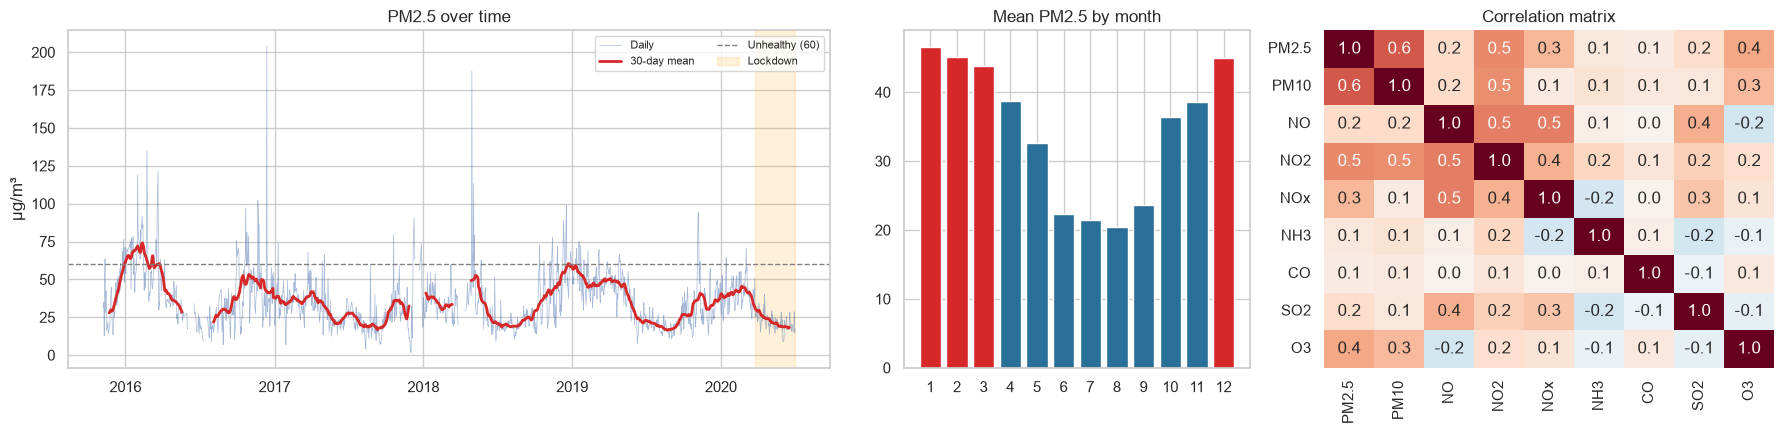

Season,Winter,Summer,Monsoon,Post-monsoon
mean PM2.5,45.6000,38.3000,21.9000,37.6000


In [ ]:
# 3. EDA: when is PM2.5 worst, and which pollutants move with it?
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5), gridspec_kw={"width_ratios": [2.2, 1, 1.3]}) #gridspec_kw is used to adjust the width ratios of the subplots

# Panel 1: daily series, 30-day mean, unhealthy line (60) and lockdown period
ax[0].plot(df["Date"], df["PM2.5"], lw=0.5, alpha=0.5, label="Daily")
ax[0].plot(df["Date"], df["PM2.5"].rolling(30, center=True).mean(), lw=2, color="#d62828", label="30-day mean")
ax[0].axhline(60, ls="--", color="grey", lw=1, label="Unhealthy (60)")
ax[0].axvspan(pd.Timestamp("2020-03-25"), df["Date"].max(), color="orange", alpha=0.15, label="Lockdown")
ax[0].set(title="PM2.5 over time", ylabel="µg/m³"); ax[0].legend(ncol=2, fontsize=8)

# Panel 2: mean PM2.5 by month (red = above 40)
monthly = df.groupby("Month")["PM2.5"].mean()
ax[1].bar(monthly.index, monthly, color=["#d62828" if v > 40 else "#2a6f97" for v in monthly])
ax[1].set(title="Mean PM2.5 by month", xticks=range(1, 13))

# Panel 3: correlations between PM2.5 and the predictors
sns.heatmap(df[["PM2.5"] + X_VARS].corr(), annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[2], cbar=False)
ax[2].set_title("Correlation matrix")
plt.tight_layout()
plt.savefig("../reports/figures/01_eda.png", dpi=150)
plt.show()

# Mean PM2.5 by season, in calendar order
df.groupby("Season")["PM2.5"].mean().reindex(ORDER).round(1).to_frame("mean PM2.5").T

**When is the air worst?** January (≈ 47 µg/m³) is the worst month and August (≈ 20) the cleanest. Winter is about **twice** the monsoon level, because rain washes particles out. PM10 (r ≈ 0.6) and the nitrogen oxides correlate most with PM2.5. NO, NO2 and NOx are related, so multicollinearity is checked in Section 6.

## 4. Simple linear regression (Unit 1)
$$PM2.5_i = \beta_0 + \beta_1 PM10_i + \varepsilon_i,\qquad \hat\beta_1=\frac{S_{xy}}{S_{xx}},\quad \hat\beta_0=\bar y-\hat\beta_1\bar x$$
Test $H_0:\beta_1=0$ with $t=\hat\beta_1/SE(\hat\beta_1)\sim t_{n-2}$; 95% CI $\hat\beta_1\pm t_{0.025,n-2}SE$; ANOVA $SST=SSR+SSE$, $F=MSR/MSE$; $R^2=SSR/SST$.

In [22]:
# 4. SLR: PM2.5 on PM10, estimated by hand and checked against statsmodels
# Least squares: b1 = Sxy/Sxx, b0 = ybar - b1*xbar
x, y = train["PM10"].values, train["PM25"].values
Sxx, Sxy = np.sum((x - x.mean()) ** 2), np.sum((x - x.mean()) * (y - y.mean()))
b1 = Sxy / Sxx; b0 = y.mean() - b1 * x.mean()
# Sums of squares: SST = SSR + SSE; MSE estimates sigma^2
SSE = np.sum((y - b0 - b1 * x) ** 2); SST = np.sum((y - y.mean()) ** 2); SSR = SST - SSE; MSE = SSE / (n - 2)
# Same model in statsmodels; the assert proves the manual results match
slr = smf.ols("PM25 ~ PM10", data=train).fit()
assert np.allclose([b0, b1], slr.params)                          # manual estimates = statsmodels

# Coefficient table: SE, t-test of H0: beta = 0, p-value and 95% CI
t_crit = stats.t.ppf(0.975, n - 2)
slr_tab = pd.DataFrame({"estimate": [b0, b1],
                        "SE": [np.sqrt(MSE * (1 / n + x.mean() ** 2 / Sxx)), np.sqrt(MSE / Sxx)]}, index=["b0", "b1 (PM10)"])
slr_tab["t"] = slr_tab["estimate"] / slr_tab["SE"]
slr_tab["p"] = 2 * stats.t.sf(slr_tab["t"].abs(), n - 2)
slr_tab["95% CI low"] = slr_tab["estimate"] - t_crit * slr_tab["SE"]
slr_tab["95% CI high"] = slr_tab["estimate"] + t_crit * slr_tab["SE"]
# ANOVA table: F = MSR/MSE tests the regression as a whole
anova = pd.DataFrame({"df": [1, n - 2, n - 1], "SS": [SSR, SSE, SST], "MS": [SSR, MSE, np.nan],
                      "F": [SSR / MSE, np.nan, np.nan], "p": [stats.f.sf(SSR / MSE, 1, n - 2), np.nan, np.nan]},
                     index=["Regression", "Residual", "Total"])
# Save tables; print R², adjusted R² and show F = t² in SLR
slr_tab.to_csv("../reports/tables/slr_coefficients.csv"); anova.to_csv("../reports/tables/slr_anova.csv")
print(f"R² = {SSR / SST:.4f} | adjusted R² = {1 - MSE / (SST / (n - 1)):.4f} | "
      f"F = {SSR / MSE:.1f} = t² = {slr_tab['t'].iloc[1] ** 2:.1f}")
display(slr_tab, anova)

R² = 0.3625 | adjusted R² = 0.3619 | F = 670.4 = t² = 670.4


,estimate,SE,t,p,95% CI low,95% CI high
b0,10.9940,1.0682,10.2923,0.0000,8.8983,13.0898
b1 (PM10),0.2804,0.0108,25.8912,0.0000,0.2591,0.3016


,df,SS,MS,F,p
Regression,1,148057.3951,148057.3951,670.3551,0.0000
Residual,1179,260398.8223,220.8641,NaN,NaN
Total,1180,408456.2174,NaN,NaN,NaN


The manual least-squares estimates equal the statsmodels ones. Each extra 1 µg/m³ of PM10 adds about **0.28 µg/m³** of PM2.5 (95% CI 0.26 to 0.30, p ≈ 0). In SLR $F=t^2$, and PM10 alone explains **36%** of the variation.

**Prediction of a new observation:** $\hat y_0 \pm t_{0.025,n-2}\sqrt{MSE\,(1+\frac1n+\frac{(x_0-\bar x)^2}{S_{xx}})}$. The prediction interval (one new day) is much wider than the confidence interval (the mean of all such days) because it adds the day-to-day noise $\sigma^2$. At PM10 = 50 the interval even dips below zero, which is impossible for a concentration; this is one reason for the log model in Section 6.

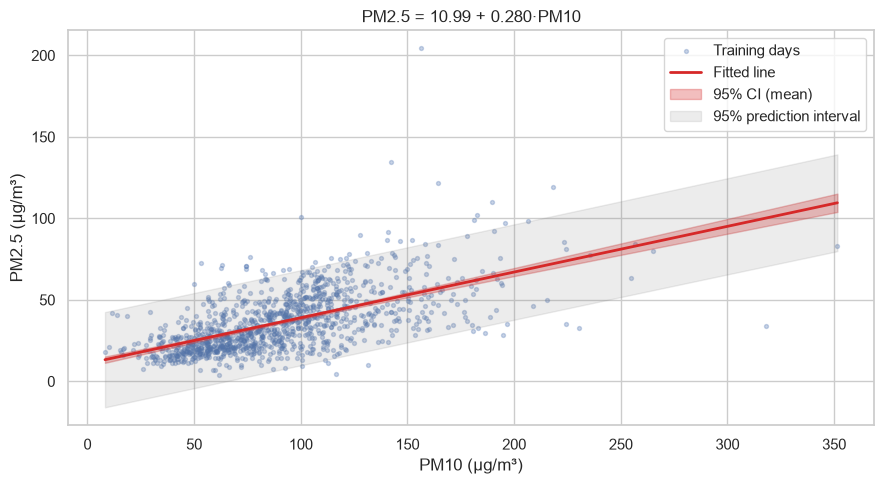

,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
PM10,,,,,
50,25.0000,23.8000,26.2000,-4.2000,54.2000
100,39.0000,38.2000,39.9000,9.9000,68.2000
150,53.1000,51.5000,54.6000,23.9000,82.2000


In [23]:
# SLR prediction: confidence interval (mean of such days) vs prediction interval (one new day)
# Intervals at PM10 = 50, 100, 150
new = slr.get_prediction(pd.DataFrame({"PM10": [50, 100, 150]})).summary_frame()
new.index = pd.Index([50, 100, 150], name="PM10")
# Intervals along the whole PM10 range, for the plot
grid = pd.DataFrame({"PM10": np.linspace(x.min(), x.max(), 200)})
band = slr.get_prediction(grid).summary_frame()
# Scatter + fitted line + CI band (narrow) + prediction band (wide)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y, s=8, alpha=0.3, label="Training days")
ax.plot(grid["PM10"], band["mean"], color="#d62828", lw=2, label="Fitted line")
ax.fill_between(grid["PM10"], band["mean_ci_lower"], band["mean_ci_upper"], color="#d62828", alpha=0.3, label="95% CI (mean)")
ax.fill_between(grid["PM10"], band["obs_ci_lower"], band["obs_ci_upper"], color="grey", alpha=0.15, label="95% prediction interval")
ax.set(xlabel="PM10 (µg/m³)", ylabel="PM2.5 (µg/m³)", title=f"PM2.5 = {b0:.2f} + {b1:.3f}·PM10"); ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/02_slr_fit.png", dpi=150)
plt.show()
# Table of the intervals at the three PM10 values
new[["mean", "mean_ci_lower", "mean_ci_upper", "obs_ci_lower", "obs_ci_upper"]].round(1)

## 5. Multiple linear regression (Unit 2)
$\mathbf y=\mathbf X\boldsymbol\beta+\boldsymbol\varepsilon$, $\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$. **Gauss-Markov:** if the errors have zero mean, constant variance and no correlation, OLS is BLUE. Model 1 uses the 8 pollutants. Model 2 adds season as dummies (Winter is the reference). Each slope is the change in PM2.5 per unit, **holding the other predictors fixed**.

In [24]:
# 5. MLR: Model 1 = pollutants only, Model 2 = pollutants + season
mlr1 = smf.ols("PM25 ~ " + " + ".join(X_VARS), data=train).fit()
mlr2 = smf.ols("PM25 ~ " + RHS, data=train).fit()
# Check the matrix formula beta = (X'X)^-1 X'y against statsmodels
X = mlr2.model.exog
assert np.allclose(np.linalg.solve(X.T @ X, X.T @ mlr2.model.endog), mlr2.params)   # (X'X)^-1 X'y = statsmodels

# Coefficient table with readable season labels
mlr_tab = pd.DataFrame({"coef": mlr2.params, "SE": mlr2.bse, "t": mlr2.tvalues, "p": mlr2.pvalues})
mlr_tab.index = mlr_tab.index.str.replace(SEASON, "Season")   # shorter season labels
mlr_tab.to_csv("../reports/tables/mlr_coefficients.csv")
# Partial F test: does season add significant information beyond the pollutants?
partial = sm.stats.anova_lm(mlr1, mlr2)
print(f"Overall F = {mlr2.fvalue:.1f} (p = {mlr2.f_pvalue:.1e}) | "
      f"partial F for Season = {partial['F'][1]:.1f} (p = {partial['Pr(>F)'][1]:.1e})")
mlr_tab

Overall F = 139.2 (p = 1.4e-203) | partial F for Season = 31.9 (p = 7.7e-20)


,coef,SE,t,p
Intercept,6.7252,2.3554,2.8552,0.0044
Season[T.Monsoon],-10.9253,1.2624,-8.6543,0.0000
Season[T.Post-monsoon],-2.3048,1.2509,-1.8425,0.0657
Season[T.Summer],-2.3434,1.1738,-1.9965,0.0461
PM10,0.1800,0.0110,16.3894,0.0000
NO,-0.2743,0.0691,-3.9669,0.0001
NO2,0.1637,0.0446,3.6681,0.0003
NOx,0.3039,0.0282,10.7842,0.0000
NH3,0.1230,0.0295,4.1739,0.0000
CO,-0.5981,0.4063,-1.4721,0.1413


Season is jointly significant (partial F test). Holding the pollutants fixed, monsoon days are about **11 µg/m³ cleaner** than winter days. PM10 and NOx have the largest t-values, which points to road dust and traffic; CO is not significant.

In [25]:
# Out-of-sample check: test RMSE and R² for SLR, MLR 1 and MLR 2
# Helper: RMSE and R² (1 - SSE/SST) on the test period
def test_scores(pred):
    err = test["PM25"] - pred
    return np.sqrt(np.mean(err ** 2)), 1 - np.sum(err ** 2) / np.sum((test["PM25"] - test["PM25"].mean()) ** 2)

# Training fit vs test performance, one row per model
pd.DataFrame({name: [m.rsquared, m.rsquared_adj, *test_scores(m.predict(test))]
              for name, m in [("SLR: PM10", slr), ("MLR 1: pollutants", mlr1), ("MLR 2: + season", mlr2)]},
             index=["R² train", "adj R² train", "RMSE test", "R² test"]).T

,R² train,adj R² train,RMSE test,R² test
SLR: PM10,0.3625,0.3619,8.0804,0.6300
MLR 1: pollutants,0.5316,0.5284,7.0188,0.7209
MLR 2: + season,0.5670,0.5630,8.5710,0.5838


Adding predictors raises the training R² from 0.36 to 0.57. On the **unseen test period** (which includes the lockdown), the raw-scale Model 2 does worse than Model 1 (test R² 0.58 vs 0.72). A good in-sample fit is not enough, so the assumptions are checked next.

## 6. Assumptions, multicollinearity and remedies (Unit 2)
- **VIF** $=1/(1-R_j^2)$; values above 5 to 10 signal multicollinearity.
- **Heteroscedasticity:** residual-vs-fitted plot and Breusch-Pagan test.
- **Normality:** Q-Q plot and Jarque-Bera test.
- **Autocorrelation:** Durbin-Watson $d=\sum(e_t-e_{t-1})^2/\sum e_t^2\approx2(1-\hat\rho)$; $d\approx2$ means no autocorrelation.

**Remedies:** a log transform for the skewed, funnel-shaped residuals, and Cochrane-Orcutt (GLSAR) for AR(1) errors.

GLSAR AR(1) rho = 0.579 | predictors still significant with HAC (Newey-West) SEs: 8 of 11


,PM10,NO,NO2,NOx,NH3,CO,SO2,O3
VIF,1.4100,2.2200,1.7900,1.7100,1.1200,1.0300,1.3700,1.3700


,MLR 2 (PM2.5),Remedy: log(PM2.5)
Residual skew,2.5915,-0.2013
Jarque-Bera p (normality),0.0000,0.0000
Breusch-Pagan p (constant variance),0.0000,0.0000
Durbin-Watson (independence),0.9991,0.9041
adj R²,0.5630,0.6091
Durbin-Watson after Cochrane-Orcutt (GLSAR),NaN,2.0708


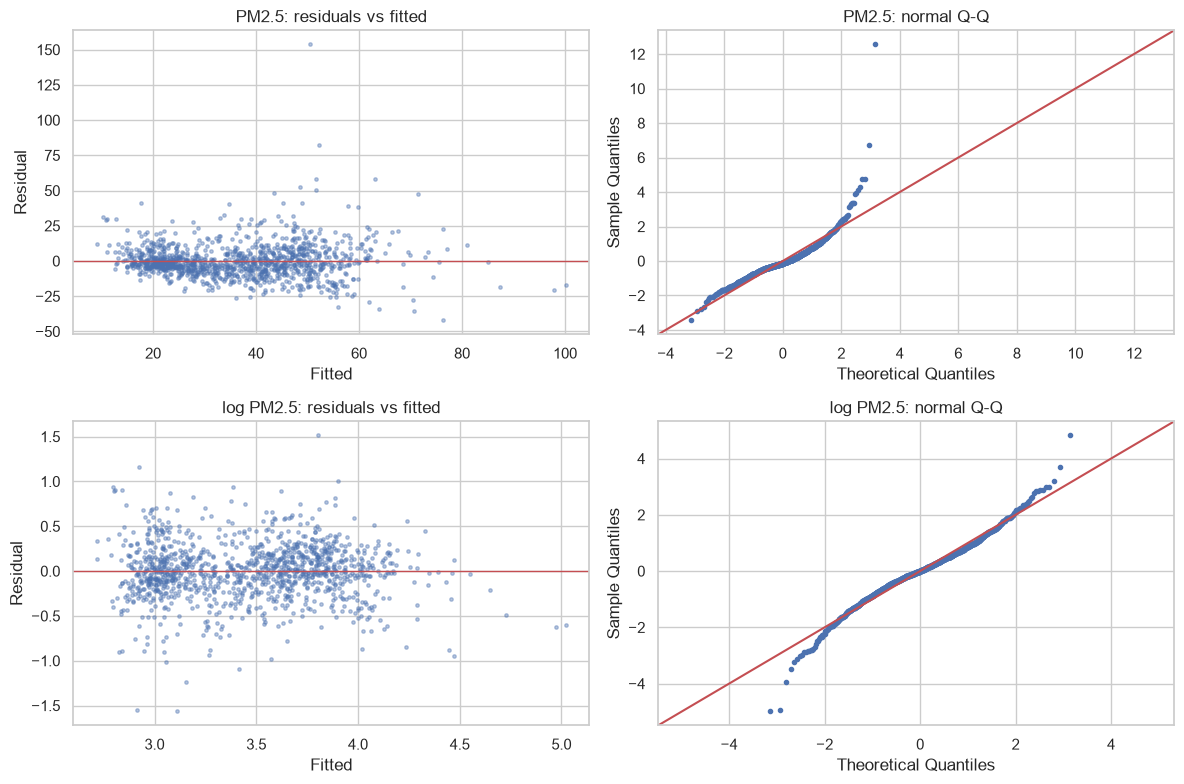

In [26]:
# 6. Assumption checks and remedies
# Remedy for skew and unequal variance: model log(PM2.5)
log2 = smf.ols("np.log(PM25) ~ " + RHS, data=train).fit()

# Normality (Jarque-Bera), constant variance (Breusch-Pagan), independence (Durbin-Watson)
def checks(m):
    jb = jarque_bera(m.resid)
    return {"Residual skew": jb[2], "Jarque-Bera p (normality)": jb[1],
            "Breusch-Pagan p (constant variance)": het_breuschpagan(m.resid, m.model.exog)[1],
            "Durbin-Watson (independence)": durbin_watson(m.resid), "adj R²": m.rsquared_adj}

# Autocorrelation remedies: Cochrane-Orcutt (GLSAR, AR(1)) and HAC/Newey-West standard errors
glsar = sm.GLSAR(log2.model.endog, log2.model.exog, rho=1).iterative_fit(maxiter=20)
hac = log2.get_robustcov_results(cov_type="HAC", maxlags=7)
# Compare the raw and log models on every check
tests = pd.DataFrame({"MLR 2 (PM2.5)": checks(mlr2), "Remedy: log(PM2.5)": checks(log2)})
tests.loc["Durbin-Watson after Cochrane-Orcutt (GLSAR)"] = [np.nan, durbin_watson(glsar.wresid)]
tests.to_csv("../reports/tables/assumption_tests.csv")
# VIF = 1/(1-R_j²) per predictor; above 5-10 signals multicollinearity
vif = pd.Series([variance_inflation_factor(sm.add_constant(train[X_VARS]).values, i) for i in range(1, 9)], index=X_VARS)
vif.to_csv("../reports/tables/vif.csv", header=["VIF"])
print(f"GLSAR AR(1) rho = {glsar.model.rho[0]:.3f} | predictors still significant with HAC (Newey-West) SEs: "
      f"{(hac.pvalues[1:] < 0.05).sum()} of {len(hac.pvalues) - 1}")
display(vif.to_frame("VIF").T.round(2), tests)

# Residuals vs fitted (funnel = heteroscedasticity) and Q-Q plots (normality), raw vs log
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for row, (m, name) in enumerate([(mlr2, "PM2.5"), (log2, "log PM2.5")]):
    ax[row, 0].scatter(m.fittedvalues, m.resid, s=6, alpha=0.4); ax[row, 0].axhline(0, color="r", lw=1)
    ax[row, 0].set(title=f"{name}: residuals vs fitted", xlabel="Fitted", ylabel="Residual")
    sm.qqplot(m.resid, line="45", fit=True, ax=ax[row, 1], markersize=3); ax[row, 1].set_title(f"{name}: normal Q-Q")
plt.tight_layout()
plt.savefig("../reports/figures/03_residual_diagnostics.png", dpi=150)

All VIFs are below 2.5, so there is **no harmful multicollinearity** and no remedy is needed. Raw residuals are strongly right-skewed (skew 2.6) with a funnel shape. The **log transform** removes most of the skew, straightens the Q-Q plot and raises adjusted R² to **0.61**. The Breusch-Pagan and Jarque-Bera tests still reject, because n is large and a few spike days remain. Durbin-Watson ≈ 0.9 shows positive autocorrelation (ρ ≈ 0.58). Cochrane-Orcutt brings d back to 2.07, and 8 of 11 terms stay significant with autocorrelation-robust (HAC) standard errors. **log MLR 2 is carried forward.**

## 7. Influence diagnostics (Unit 3)
**Added-variable plots** show each predictor's effect after removing all the other predictors; the slope of each panel equals its coefficient in the full log model.

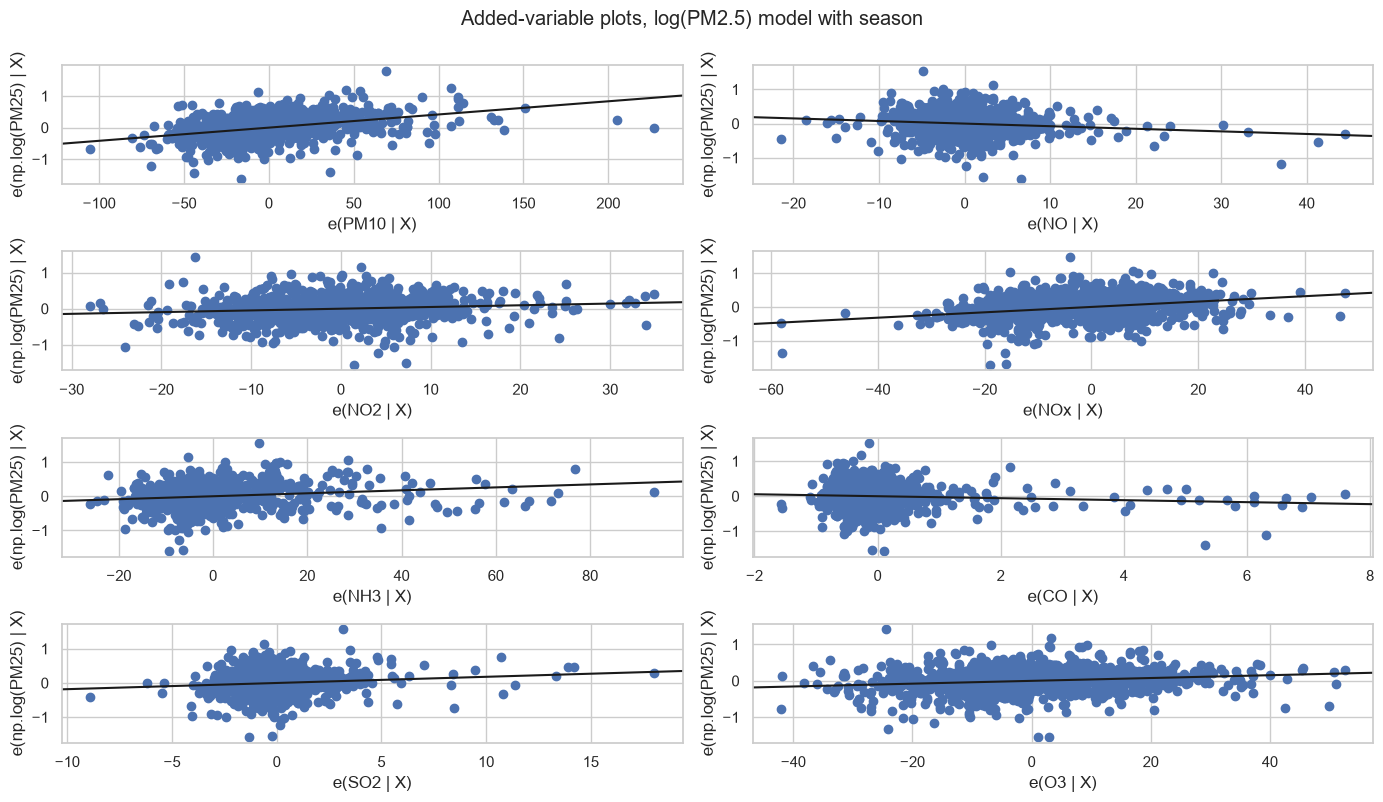

In [27]:
# 7. Added-variable plots: each predictor's effect after removing the others (slope = its coefficient)
fig = plt.figure(figsize=(14, 8))
sm.graphics.plot_partregress_grid(log2, exog_idx=X_VARS, fig=fig)
fig.suptitle("Added-variable plots, log(PM2.5) model with season", y=1.0)
plt.tight_layout()
plt.savefig("../reports/figures/04_added_variable_plots.png", dpi=150)

| Measure | Detects | Formula |
|---|---|---|
| Studentized deleted residual $t_i$ | outlying Y | $e_i\sqrt{\frac{n-p-1}{SSE(1-h_{ii})-e_i^2}}$ |
| Leverage $h_{ii}$ | outlying X | diagonal of $\mathbf H=\mathbf X(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top$ |
| DFFITS | influence on own fit | $t_i\sqrt{h_{ii}/(1-h_{ii})}$ |
| Cook's D | influence on all fits | $\frac{e_i^2}{p\,MSE}\frac{h_{ii}}{(1-h_{ii})^2}$ |
| DFBETAS | influence on each coefficient | $(\hat\beta_k-\hat\beta_{k(i)})/SE$ |

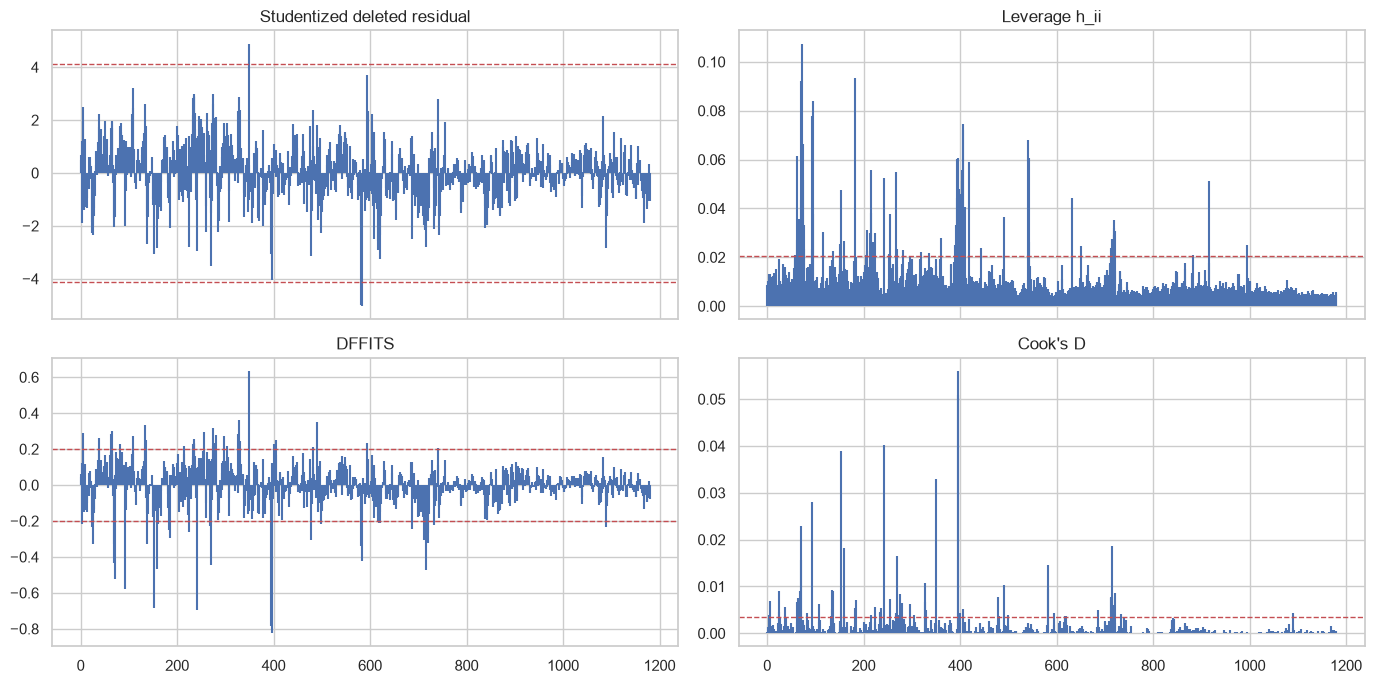

Most influential day: 2017-01-29 (PM2.5 = 6.8, Cook's D = 0.056)


,rule,cut-off,days flagged
Studentized deleted residual,"|t_i| > t(1-α/2n, n-p-1)",4.1100,3
Leverage h_ii,h_ii > 2p/n,0.0203,79
DFFITS,|DFFITS| > 2√(p/n),0.2016,74
Cook's D,D_i > 4/n,0.0034,72
DFBETAS (any coefficient),|DFBETAS| > 2/√n,0.0582,268


In [28]:
# Influence diagnostics on the final log model
# Studentized deleted residuals (outlying Y), leverage (outlying X), DFFITS and Cook's D (influence)
infl = log2.get_influence()
p = int(log2.df_model) + 1
measures = pd.DataFrame({"Studentized deleted residual": infl.resid_studentized_external,
                         "Leverage h_ii": infl.hat_matrix_diag, "DFFITS": infl.dffits[0], "Cook's D": infl.cooks_distance[0]})
# Standard cut-offs (Bonferroni-corrected for the residuals)
cut = {"Studentized deleted residual": stats.t.ppf(1 - 0.05 / (2 * n), n - p - 1), "Leverage h_ii": 2 * p / n,
       "DFFITS": 2 * np.sqrt(p / n), "Cook's D": 4 / n, "DFBETAS (any coefficient)": 2 / np.sqrt(n)}
# Count the days that cross each cut-off
flagged = [int((measures[k].abs() > cut[k]).sum()) for k in measures]
flagged.append(int((np.abs(infl.dfbetas) > cut["DFBETAS (any coefficient)"]).any(axis=1).sum()))
# Summary table: rule, cut-off, days flagged
infl_tab = pd.DataFrame({"rule": ["|t_i| > t(1-α/2n, n-p-1)", "h_ii > 2p/n", "|DFFITS| > 2√(p/n)", "D_i > 4/n", "|DFBETAS| > 2/√n"],
                         "cut-off": list(cut.values()), "days flagged": flagged}, index=list(cut))
infl_tab.to_csv("../reports/tables/influence_summary.csv")

# Stem plot of each measure with its cut-off line(s)
fig, ax = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for a, col in zip(ax.ravel(), measures):
    a.stem(measures[col], markerfmt=" ", basefmt=" ")
    a.axhline(cut[col], color="r", ls="--", lw=1)
    if col in ("Studentized deleted residual", "DFFITS"):
        a.axhline(-cut[col], color="r", ls="--", lw=1)
    a.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/05_influence_measures.png", dpi=150)
plt.show()
# Report the single most influential day
top, top_d = measures["Cook's D"].idxmax(), measures["Cook's D"].max()
print(f"Most influential day: {train.loc[top, 'Date'].date()} (PM2.5 = {train.loc[top, 'PM25']:.1f}, Cook's D = {top_d:.3f})")
infl_tab

The AV plots show clear linear partial effects for PM10 and NOx, a negative one for NO, and an almost flat line for CO. Only **3 days** are outlying in Y after the Bonferroni correction, and the largest Cook's D is only 0.056 (far below 1), so no single day controls the fit. The most influential day, 29 Jan 2017, is an unusually clean winter day (PM2.5 = 6.8). The flagged days are real pollution events, so they are kept.

## 8. Model selection: AIC, BIC and Mallows' Cp (Unit 3)
All $2^9-1 = 511$ subsets of the 8 pollutants plus season are fitted to log(PM2.5).
$$AIC=n\ln\frac{SSE}{n}+2p,\qquad BIC=n\ln\frac{SSE}{n}+p\ln n,\qquad C_p=\frac{SSE_p}{MSE_{full}}-(n-2p)$$
Lower AIC/BIC is better; a good model has $C_p$ small and close to $p$.

In [29]:
# 8. All-subsets selection: every combination of predictors, with and without season
rows = []
for use_season in (False, True):
    for k in range(len(X_VARS) + 1):
        for subset in combinations(X_VARS, k):
            terms = list(subset) + [SEASON] * use_season
            if not terms:
                continue
            # Fit the subset; record p, adj R², AIC, BIC and Mallows' Cp
            m = smf.ols("np.log(PM25) ~ " + " + ".join(terms), data=train).fit()
            q = int(m.df_model) + 1
            rows.append({"model": ", ".join(subset) + " + Season" * use_season, "p": q, "adj R²": m.rsquared_adj,
                         "AIC": n * np.log(m.ssr / n) + 2 * q, "BIC": n * np.log(m.ssr / n) + q * np.log(n),
                         "Cp": m.ssr / log2.mse_resid - (n - 2 * q)})
# Best model by each criterion (lowest value) plus the runner-up by Cp
subsets = pd.DataFrame(rows)
best = pd.DataFrame({f"Best by {c}": subsets.loc[subsets[c].idxmin()] for c in ["AIC", "BIC", "Cp"]}).T
best.loc["Runner-up by Cp"] = subsets.sort_values("Cp").iloc[1]
best.to_csv("../reports/tables/model_selection.csv")
print(f"{len(subsets)} candidate models compared")
best

511 candidate models compared


,model,p,adj R²,AIC,BIC,Cp
Best by AIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Best by BIC,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Best by Cp,"PM10, NO, NO2, NOx, NH3, CO, SO2, O3 + Season",12,0.6091,-2713.6386,-2652.7492,12.0000
Runner-up by Cp,"PM10, NO, NO2, NOx, NH3, SO2, O3 + Season",11,0.6070,-2708.2336,-2652.4183,17.3528


All three criteria choose the **full model: 8 pollutants + season** (p = 12). The best smaller model (without CO) has $C_p$ well above $p$, so dropping any variable adds bias. **Final model: log MLR 2.**

## 9. Ridge and LASSO regularisation (Unit 2)
$$\text{Ridge: }\min_\beta \|y-X\beta\|^2+\alpha\sum\beta_j^2\qquad\text{LASSO: }\min_\beta \tfrac{1}{2n}\|y-X\beta\|^2+\alpha\sum|\beta_j|$$
Ridge shrinks every coefficient (a remedy for multicollinearity); LASSO can set coefficients to exactly zero (variable selection). Features are standardised, and α is chosen by **5-fold expanding-window time-series CV** on the training period, with the scaler re-fitted inside each fold to avoid leakage.

In [30]:
# 9. Ridge and LASSO on log(PM2.5), alpha chosen by time-series cross-validation
# Design matrix: 8 pollutants + 3 season dummies (Winter = reference)
def design(d):
    return d[X_VARS].assign(**{s: (d["Season"] == s).astype(int) for s in ["Summer", "Monsoon", "Post-monsoon"]})

X_tr, X_te, y_tr = design(train), design(test), np.log(train["PM25"])
# Expanding-window CV: the first year is always training; each fold validates on later data
first_year = int((train["Date"] < train["Date"].min() + pd.DateOffset(years=1)).sum())
ts_cv = TimeSeriesSplit(n_splits=5, test_size=(n - first_year) // 5)          # expanding window, never sees the future

# Baseline OLS, then grid-search alpha for Ridge and LASSO (features standardised)
models = {"OLS": make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, y_tr)}
for name, est, alphas, score in [("Ridge", Ridge(), np.logspace(-3, 4, 80), "neg_root_mean_squared_error"),
                                 ("LASSO", Lasso(max_iter=50000), np.logspace(-5, 0, 80), "neg_mean_squared_error")]:
    search = GridSearchCV(make_pipeline(StandardScaler(), est), {f"{type(est).__name__.lower()}__alpha": alphas},
                          cv=ts_cv, scoring=score)
    models[name] = search.fit(X_tr, y_tr).best_estimator_                     # scaler re-fitted inside every CV fold

# Convert log predictions back to µg/m³; Duan smearing corrects the bias of exp()
def pm25_pred(m):                                                              # back-transform with Duan smearing
    return np.exp(m.predict(X_te)) * np.mean(np.exp(y_tr - m.predict(X_tr)))

# Coefficients, chosen alpha, non-zero count and test scores per model
reg = pd.DataFrame({name: m[-1].coef_ for name, m in models.items()}, index=X_tr.columns)
reg.loc["alpha"] = [np.nan, models["Ridge"][-1].alpha, models["LASSO"][-1].alpha]
reg.loc["non-zero coefficients"] = [(np.abs(m[-1].coef_) > 1e-8).sum() for m in models.values()]
scores = [test_scores(pm25_pred(m)) for m in models.values()]
reg.loc["RMSE test"], reg.loc["R² test"] = [s[0] for s in scores], [s[1] for s in scores]
reg.to_csv("../reports/tables/regularisation_results.csv")
reg

,OLS,Ridge,LASSO
PM10,0.1663,0.1568,0.1640
NO,-0.0601,-0.0476,-0.0469
NO2,0.0566,0.0619,0.0558
NOx,0.1354,0.1213,0.1268
NH3,0.0560,0.0504,0.0506
CO,-0.0260,-0.0222,-0.0192
SO2,0.0416,0.0395,0.0372
O3,0.0714,0.0760,0.0714
Summer,-0.0128,-0.0040,-0.0008
Monsoon,-0.1730,-0.1586,-0.1633


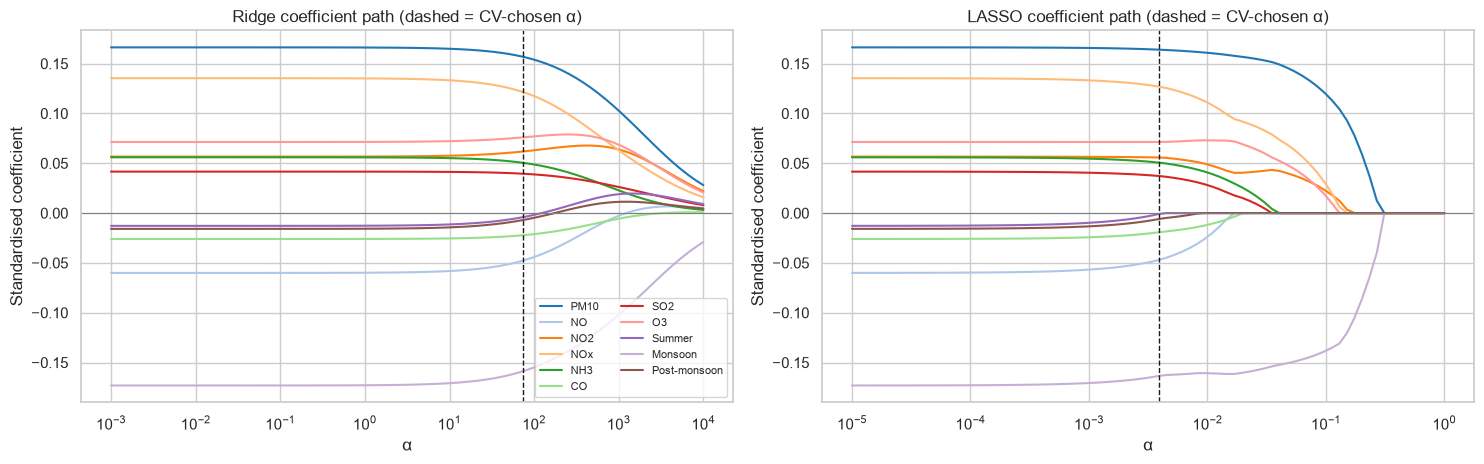

In [31]:
# Coefficient paths: how each standardised coefficient shrinks as alpha grows
# Refit Ridge and LASSO over a grid of alphas
Xs = StandardScaler().fit_transform(X_tr)
alphas_r = np.logspace(-3, 4, 80)
ridge_path = np.array([Ridge(alpha=a).fit(Xs, y_tr).coef_ for a in alphas_r])
alphas_l, lasso_coefs, _ = lasso_path(Xs, y_tr.values, alphas=np.logspace(0, -5, 80))
# Plot the paths; dashed line = alpha chosen by cross-validation
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
for a in ax: a.set_prop_cycle(color=sns.color_palette("tab20", X_tr.shape[1]))
ax[0].plot(alphas_r, ridge_path); ax[1].plot(alphas_l, lasso_coefs.T)
for a, name in zip(ax, ["Ridge", "LASSO"]):
    a.axvline(models[name][-1].alpha, color="k", ls="--", lw=1); a.axhline(0, color="grey", lw=0.8)
    a.set(xscale="log", title=f"{name} coefficient path (dashed = CV-chosen α)", xlabel="α", ylabel="Standardised coefficient")
ax[0].legend(X_tr.columns, fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("../reports/figures/06_ridge_lasso_paths.png", dpi=150)

The CV-chosen penalties are α = 74.7 (Ridge) and α = 0.0039 (LASSO). Both keep all 11 features and shrink them only slightly, mostly the weak Summer/Post-monsoon dummies, NO and CO. Test RMSE improves only marginally (7.9 vs 8.05 µg/m³ for OLS). This agrees with the VIF result: multicollinearity is low, so regularisation brings little gain, and the OLS log model remains the interpretable choice.

## 10. Categorical data analysis and logistic regression (Unit 4)
**Contingency table and χ² test.** $H_0$: air quality status is independent of season. $\chi^2=\sum\frac{(O-E)^2}{E}$ with $(r-1)(c-1)$ df. **Odds ratio** $OR=\frac{ad}{bc}$, 95% CI $\exp(\ln OR\pm1.96\sqrt{\tfrac1a+\tfrac1b+\tfrac1c+\tfrac1d})$.

In [32]:
# 10. Contingency table: is air-quality status independent of season?
# Season x status table (all days with a PM2.5 reading)
days = df.dropna(subset=["PM2.5"])
obs = pd.crosstab(days["Season"], days["Unhealthy"]).reindex(ORDER).set_axis(["Acceptable", "Unhealthy"], axis=1)
# Chi-square test of independence; Cramér's V measures strength (0 to 1)
chi2, p_chi, dof, expected = stats.chi2_contingency(obs)
cramers_v = np.sqrt(chi2 / (obs.values.sum() * (min(obs.shape) - 1)))

# 2x2 table winter vs other seasons -> odds ratio and its 95% CI on the log scale
a, b = obs.loc["Winter", "Unhealthy"], obs.loc["Winter", "Acceptable"]
c, d = obs.drop("Winter")["Unhealthy"].sum(), obs.drop("Winter")["Acceptable"].sum()
odds_ratio, se_log = (a * d) / (b * c), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
print(f"χ² = {chi2:.1f}, df = {dof}, p = {p_chi:.1e}, Cramér's V = {cramers_v:.2f}, smallest expected count = {expected.min():.1f}")
print(f"Odds ratio (winter vs other seasons) = {odds_ratio:.2f}, 95% CI "
      f"[{np.exp(np.log(odds_ratio) - 1.96 * se_log):.2f}, {np.exp(np.log(odds_ratio) + 1.96 * se_log):.2f}]")
# Table with % unhealthy days per season
obs.assign(**{"% unhealthy": (obs["Unhealthy"] / obs.sum(axis=1) * 100).round(1)})

χ² = 111.4, df = 3, p = 5.4e-24, Cramér's V = 0.26, smallest expected count = 24.2
Odds ratio (winter vs other seasons) = 4.40, 95% CI [3.11, 6.22]


,Acceptable,Unhealthy,% unhealthy
Season,,,
Winter,355,86,19.5000
Summer,414,30,6.8000
Monsoon,495,1,0.2000
Post-monsoon,236,32,11.9000


Status clearly depends on season. Almost 1 in 5 winter days is unhealthy, compared with almost none in the monsoon. The **odds of an unhealthy day are about 4.4× higher in winter**.

**Logistic regression.** $\text{logit}(\pi)=\ln\frac{\pi}{1-\pi}=\beta_0+\beta^\top x$, fitted by maximum likelihood on the training period. $e^{\beta_j}$ is the odds ratio per unit (shown per 10 µg/m³ for the gases). Inference uses Wald tests for each coefficient and the likelihood-ratio test $G^2=-2(\ell_0-\ell_1)\sim\chi^2_k$ overall.

In [33]:
# Logistic regression: probability of an unhealthy day (PM2.5 > 60)
logit = smf.logit("Unhealthy ~ " + " + ".join(X_VARS) + " + Winter", data=train).fit(disp=False)
# Odds ratios per 10 µg/m³ for the gases (per 1 unit for CO and Winter)
unit = pd.Series(10.0, index=logit.params.index); unit[["Intercept", "CO", "Winter"]] = 1
or_tab = pd.DataFrame({"coef (log-odds)": logit.params, "p (Wald)": logit.pvalues, "per unit": unit,
                       "odds ratio": np.exp(logit.params * unit),
                       "OR 95% CI low": np.exp(logit.conf_int()[0] * unit),
                       "OR 95% CI high": np.exp(logit.conf_int()[1] * unit)}).drop("Intercept")
# Save; likelihood-ratio test of the whole model and McFadden pseudo-R²
or_tab.to_csv("../reports/tables/logistic_odds_ratios.csv")
print(f"Likelihood-ratio test: G² = {logit.llr:.1f}, df = {int(logit.df_model)}, p = {logit.llr_pvalue:.1e} | "
      f"McFadden pseudo-R² = {logit.prsquared:.3f}")
or_tab

Likelihood-ratio test: G² = 296.6, df = 9, p = 1.4e-58 | McFadden pseudo-R² = 0.368


,coef (log-odds),p (Wald),per unit,odds ratio,OR 95% CI low,OR 95% CI high
PM10,0.0290,0.0000,10.0000,1.3367,1.2508,1.4286
NO,-0.0105,0.6370,10.0000,0.9001,0.5812,1.3939
NO2,0.0265,0.0335,10.0000,1.3037,1.0210,1.6647
NOx,0.0438,0.0000,10.0000,1.5502,1.3046,1.8419
NH3,0.0092,0.2793,10.0000,1.0961,0.9282,1.2943
CO,0.0475,0.7299,1.0000,1.0486,0.8009,1.3728
SO2,0.1407,0.0080,10.0000,4.0848,1.4428,11.5644
O3,0.0130,0.0730,10.0000,1.1386,0.9879,1.3123
Winter,0.8326,0.0020,1.0000,2.2992,1.3545,3.9030


Every 10 µg/m³ of PM10 raises the odds of an unhealthy day by about 34%, and NOx, NO2, SO2 and winter are also significant. The LR test is strongly significant.

**Predictive power.** Sensitivity = TP/(TP+FN), specificity = TN/(TN+FP). The ROC curve plots sensitivity against 1 − specificity over all thresholds, and AUC summarises it. Unhealthy days are rare (≈ 11%), so the threshold is set by Youden's $J$ = sensitivity + specificity − 1 on the training data, not at 0.5.

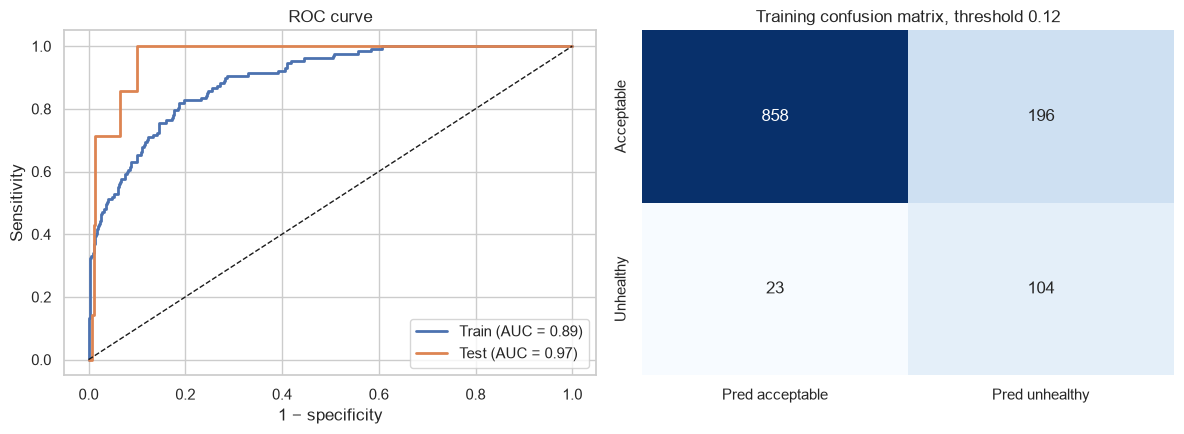

,unhealthy days,caught,sensitivity,specificity,AUC
Train,127.0000,104.0000,0.8189,0.8140,0.8944
Test,7.0000,7.0000,1.0000,0.8483,0.9685


In [34]:
# Classification performance: threshold, sensitivity/specificity, ROC and AUC
# Predicted probabilities; threshold from Youden's J on training data (unhealthy days are rare)
p_tr, p_te = logit.predict(train), logit.predict(test)
fpr, tpr, thr = roc_curve(train["Unhealthy"], p_tr)
cutoff = thr[np.argmax(tpr - fpr)]                                            # Youden's J, chosen on training data

# Confusion-matrix counts -> sensitivity, specificity and AUC
def classify(y, prob):
    tn, fp, fn, tp = confusion_matrix(y, prob >= cutoff, labels=[0, 1]).ravel()
    return {"unhealthy days": tp + fn, "caught": tp, "sensitivity": tp / (tp + fn),
            "specificity": tn / (tn + fp), "AUC": roc_auc_score(y, prob)}

clf = pd.DataFrame({"Train": classify(train["Unhealthy"], p_tr), "Test": classify(test["Unhealthy"], p_te)}).T
clf.to_csv("../reports/tables/logistic_classification_metrics.csv")

# ROC curves (train vs test) and the training confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for y_, p_, lab in [(train["Unhealthy"], p_tr, "Train"), (test["Unhealthy"], p_te, "Test")]:
    f, t, _ = roc_curve(y_, p_)
    ax[0].plot(f, t, lw=2, label=f"{lab} (AUC = {roc_auc_score(y_, p_):.2f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set(title="ROC curve", xlabel="1 − specificity", ylabel="Sensitivity"); ax[0].legend()
sns.heatmap(confusion_matrix(train["Unhealthy"], p_tr >= cutoff), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=["Pred acceptable", "Pred unhealthy"], yticklabels=["Acceptable", "Unhealthy"])
ax[1].set_title(f"Training confusion matrix, threshold {cutoff:.2f}")
plt.tight_layout()
plt.savefig("../reports/figures/07_roc_confusion.png", dpi=150)
plt.show()
clf

At the Youden threshold the model catches **82% of unhealthy training days** while correctly clearing 81% of acceptable days (AUC 0.89). On the test period it catches all 7 unhealthy days, but 7 is too few to judge reliably.

## 11. Results and conclusion

In [35]:
# 11. Final comparison of all models on the same test metrics
final = pd.DataFrame({
    "SLR: PM10": [slr.rsquared_adj, *test_scores(slr.predict(test))],
    "MLR 2: pollutants + season": [mlr2.rsquared_adj, *test_scores(mlr2.predict(test))],
    "Final: log MLR 2": [log2.rsquared_adj, *test_scores(pm25_pred(models["OLS"]))],
    "Ridge (log)": [np.nan, *test_scores(pm25_pred(models["Ridge"]))],
    "LASSO (log)": [np.nan, *test_scores(pm25_pred(models["LASSO"]))],
}, index=["adj R² (train)", "RMSE test (µg/m³)", "R² test"]).T
final.to_csv("../reports/tables/final_results.csv")
final.round(3)

,adj R² (train),RMSE test (µg/m³),R² test
SLR: PM10,0.3620,8.0800,0.6300
MLR 2: pollutants + season,0.5630,8.5710,0.5840
Final: log MLR 2,0.6090,8.0500,0.6330
Ridge (log),NaN,7.9150,0.6450
LASSO (log),NaN,7.9050,0.6460


1. **When:** Bengaluru's air is worst in winter (Dec to Feb, peak in January) and cleanest in the monsoon (Jun to Sep), about a 2× difference.
2. **What drives PM2.5:** PM10 alone explains 36%; the final **log MLR 2** (8 pollutants + season, chosen by AIC, BIC and Cp) explains **61%** and predicts the unseen test period with **R² ≈ 0.63**. PM10, NOx and season matter most, pointing to road dust and traffic.
3. **Diagnostics:** the log transform fixed the skew and funnel shape; multicollinearity is low (VIF < 2.5), so Ridge/LASSO add little; no single day dominates the fit.
4. **Unhealthy days:** winter raises the odds 4.4×; the logistic model reaches AUC ≈ 0.89 and catches about 82% of unhealthy days.

**Limitations:** residuals remain autocorrelated and mildly heteroscedastic (handled with GLSAR and HAC standard errors, not removed); no weather variables are available (season is a proxy); the test period contains the COVID lockdown and only 7 unhealthy days.